# Was passiert, wenn eine Fliegenzelle das Protein *pasilla* verliert?

Die meisten Gene werden nicht am Stück abgelesen: Die Zelle schneidet die mRNA und fügt die Stücke wieder zusammen, das nennt man **Spleißen**. Proteine, die an RNA binden, entscheiden, wie geschnitten wird. Eines davon heißt bei der Fruchtfliege *Drosophila melanogaster* **pasilla**. (Fliegengene haben oft lustige Namen; in den Daten heißt das pasilla-Gen **`ps`**.)

Forschende (Brooks et al. 2011) haben pasilla in Fliegenzellen mit **RNA-Interferenz** ausgeschaltet (**Knockdown**): Sie haben RNA hinzugefügt, die die Zelle dazu bringt, die pasilla-mRNA zu zerstören. Sequenziert wurden **4 Kontroll-** und **3 Knockdown**-Proben. Manche Proben wurden mit einer älteren Methode sequenziert (**single-end**: jedes RNA-Stück von einer Seite gelesen), manche mit einer neueren (**paired-end**: von beiden Seiten gelesen).

### Deine Forschungsfrage

> Hat der Knockdown funktioniert? Und welche Gene verändern sich, wenn pasilla fehlt?

Der Datensatz heißt `"pasilla"`.

In [1]:
setLanguage("de")   # Sprache der Ausgaben und Grafiken

Sprache: Deutsch



In [2]:
data <- loadDataset("pasilla")
data$samples

Datensatz 'pasilla' geladen: 14599 Gene, 7 Proben.



,sample,condition,library
,<chr>,<fct>,<fct>
untreated1,untreated1,control,single_end
untreated2,untreated2,control,single_end
untreated3,untreated3,control,paired_end
untreated4,untreated4,control,paired_end
treated1,treated1,knockdown,single_end
treated2,treated2,knockdown,paired_end
treated3,treated3,knockdown,paired_end


### Deine Schritte

Gehe dieselben Schritte wie im Tutorial durch. Du kannst Code aus `01_tutorial_milk.ipynb` kopieren und anpassen: Die **Spaltennamen** und **Gruppennamen** sind hier anders. Unter jedem Schritt gibt es eine Zelle für deinen Code und einen Tipp, den du öffnen kannst, wenn du nicht weiterkommst.

| Schritt | Funktionen aus dem Tutorial |
|---|---|
| 1 Daten ansehen | `DGEList`, `plotLibrarySizes` |
| 2 Gruppen festlegen | `dge$samples$group <- …`, `table`, `plotGene` |
| 3 Vorbereiten | `filterByExpr`, `normLibSizes`, `plotDistributions`, `plotSamples` |
| 4 Design und Kontrast | `model.matrix`, `makeContrasts` |
| 5 Testen | `voom`, `lmFit`, `contrasts.fit`, `eBayes`, `decideTests` |
| 6 Deuten | `plotVolcano`, `showTop`, `plotGene` |

Wenn eine Zelle einen Fehler meldet: Lies die Meldung, prüfe die Schreibweise der Namen und ob du die Zellen darüber ausgeführt hast.

## 1 Daten ansehen

Erstelle eine `DGEList` und sieh dir die Bibliotheksgrößen an. Färbe sie nach `library`. Was fällt dir auf?

[1] 14599     7

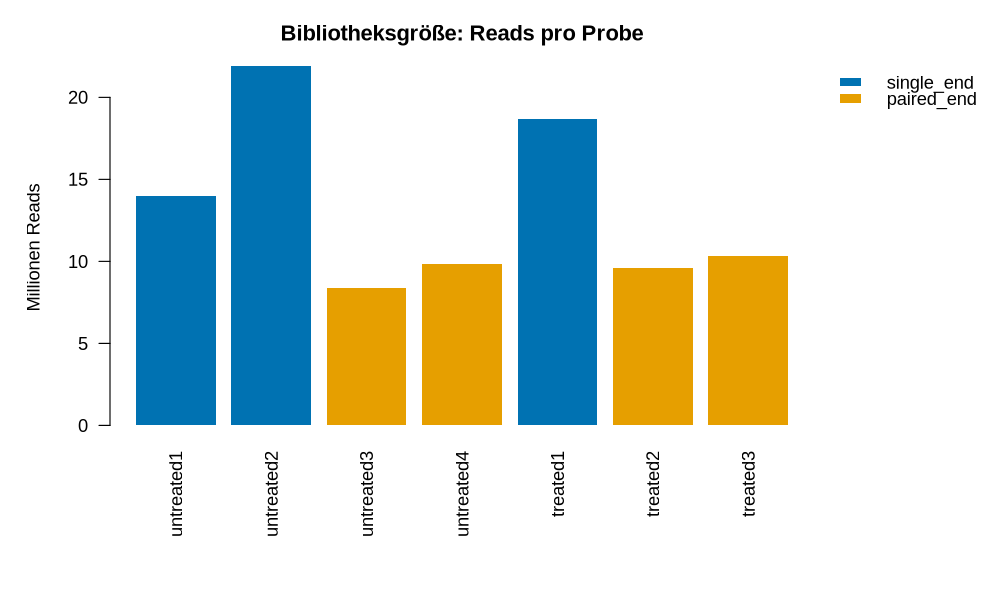

In [3]:
dge <- DGEList(counts = data$counts, samples = data$samples, genes = data$genes)
dim(dge)
plotLibrarySizes(dge, colour_by = "library")

<details><summary>💡 <b>Tipp</b> (zum Öffnen klicken)</summary>

Wie im Tutorial: `DGEList(counts = data$counts, samples = data$samples, genes = data$genes)`.

</details>

**Frage: Wie unterschiedlich sind die Bibliotheksgrößen?**

✅ **Antwort:** Zwischen etwa **8 und 22 Millionen** Reads, fast 3-mal so viele in der größten wie in der kleinsten. Die Single-end-Proben haben mehr Reads. Das ist kein Problem: Die Normalisierung gleicht es aus.

## 2 Gruppen und eine Positivkontrolle

Lege die Gruppen fest (Spalte `condition`). Prüfe dann als Allererstes, ob der Knockdown funktioniert hat: Sieh dir das Gen `ps` selbst an. So eine Prüfung, bei der man die erwartete Antwort kennt, heißt **Positivkontrolle**.


  control knockdown 
        4         3 

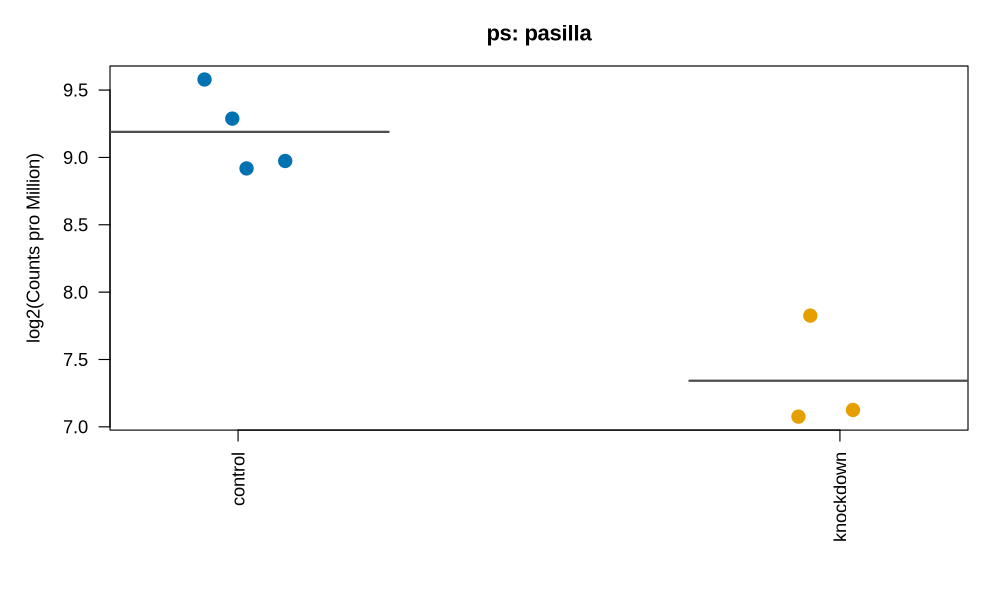

In [4]:
dge$samples$group <- dge$samples$condition
table(dge$samples$group)
plotGene(dge, "ps", group_by = "condition")

<details><summary>💡 <b>Tipp</b> (zum Öffnen klicken)</summary>

`dge$samples$group <- dge$samples$condition`, dann `plotGene(dge, "ps", group_by = "condition")`.

</details>

## 3 Vorbereiten

Filtere, normalisiere und zeichne die Probenkarte: färbe sie nach `condition`, dann nach `library`.

[1] 7919    7

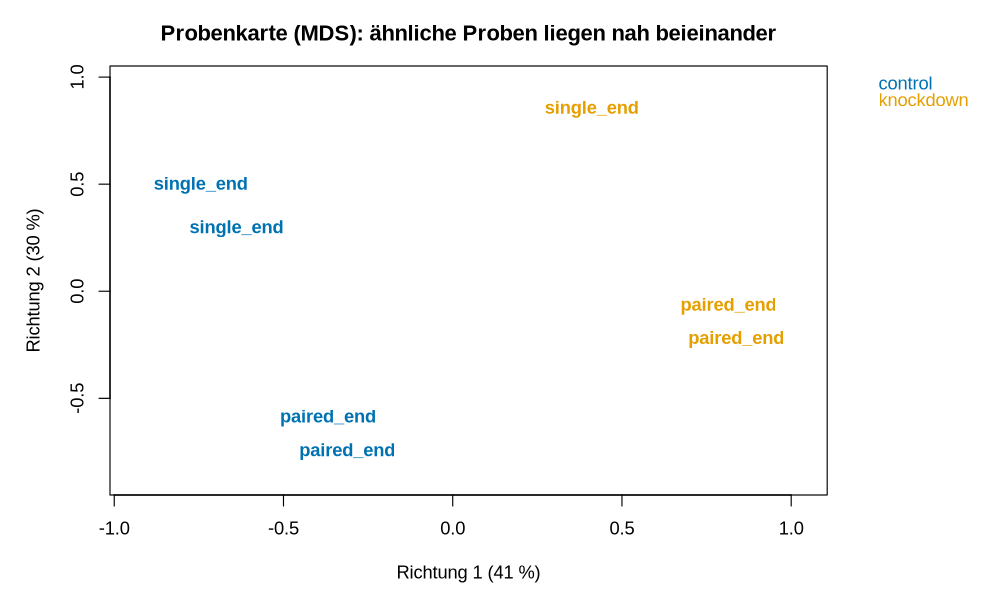

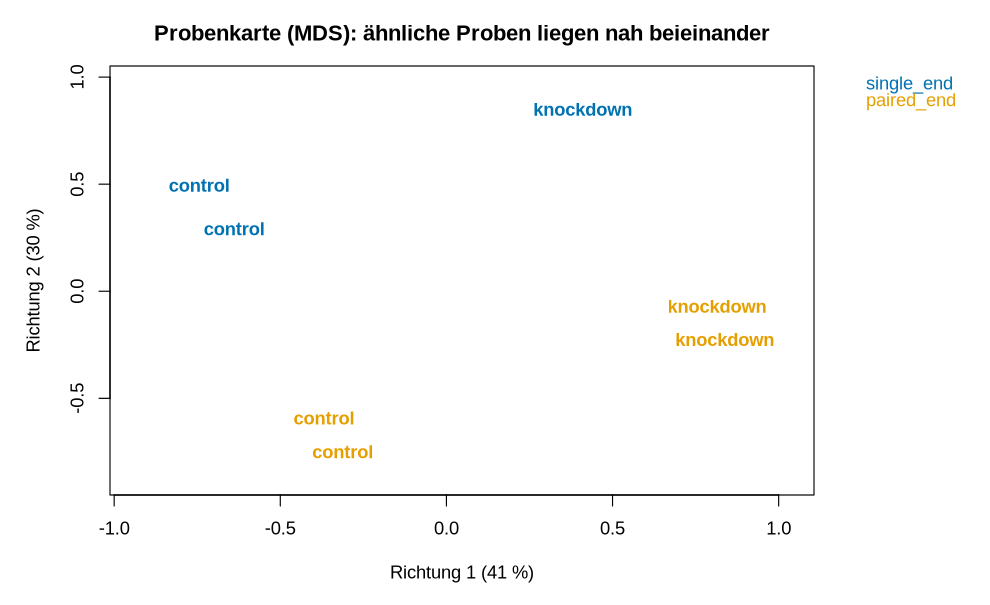

In [5]:
keep <- filterByExpr(dge)
dge <- dge[keep, , keep.lib.sizes = FALSE]
dge <- normLibSizes(dge)
dim(dge)
plotSamples(dge, colour_by = "condition", label_by = "library")
plotSamples(dge, colour_by = "library", label_by = "condition")

<details><summary>💡 <b>Tipp</b> (zum Öffnen klicken)</summary>

Wie Teil 3 des Tutorials. Für die zweite Karte: `plotSamples(dge, colour_by = "library", label_by = "condition")`.

</details>

**Frage: Was trennt die Proben entlang Richtung 1 und entlang Richtung 2?**

✅ **Antwort:** Richtung 1 (41 %) trennt **Kontrolle von Knockdown**. Richtung 2 (30 %) trennt **Single-end- von Paired-end-Proben**. Die Sequenziermethode verändert die Counts etwas, obwohl die Biologie dieselbe ist. So einen technischen Unterschied nennt man **Batch-Effekt**.

## 4 Design und Kontrast

Der Batch-Effekt aus Schritt 3 ist ein Problem: Er bringt Schwankungen hinein, die nichts mit pasilla zu tun haben. Du kannst limma davon erzählen, indem du die Bibliotheksart ins Design aufnimmst:

```r
design <- model.matrix(~0 + condition + library, data = dge$samples)
```

Sieh dir die Spaltennamen an und schreibe dann den Kontrast `knockdown_vs_control`.

In [6]:
design <- model.matrix(~0 + condition + library, data = dge$samples)
colnames(design)
contrasts <- makeContrasts(knockdown_vs_control = conditionknockdown - conditioncontrol, levels = design)
contrasts

[1] "conditioncontrol"   "conditionknockdown" "librarypaired_end"

,knockdown_vs_control
conditioncontrol,-1
conditionknockdown,1
librarypaired_end,0


<details><summary>💡 <b>Tipp</b> (zum Öffnen klicken)</summary>

Die Spalten heißen `conditioncontrol`, `conditionknockdown` und `librarypaired_end`. Der Kontrast: `conditionknockdown - conditioncontrol`.

</details>

## 5 Testen

Teste jedes Gen und zähle die signifikanten.

       knockdown_vs_control
Down                    601
NotSig                 6660
Up                      658

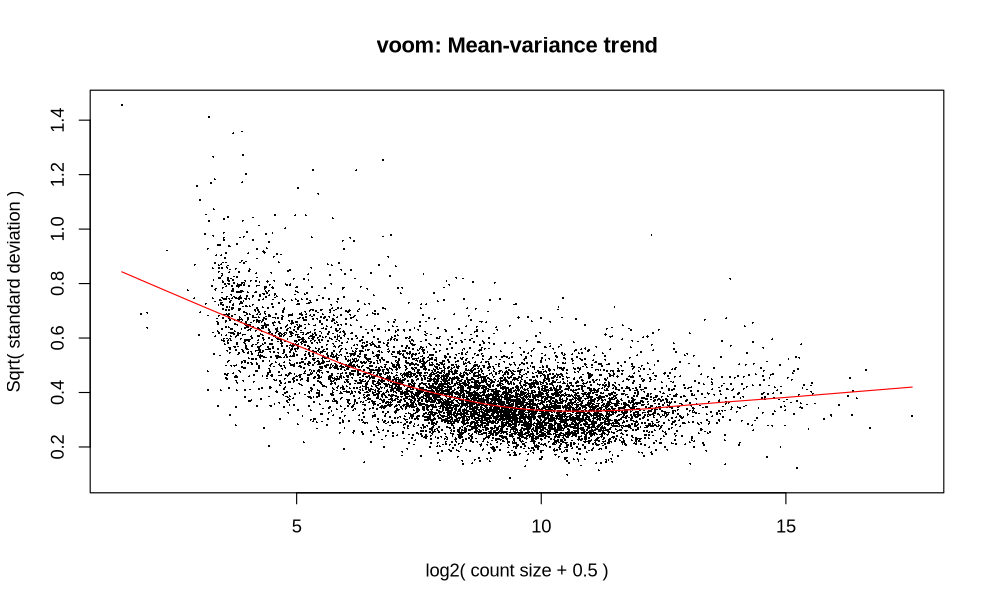

In [7]:
v <- voom(dge, design, plot = TRUE)
fit <- lmFit(v, design)
fit <- contrasts.fit(fit, contrasts)
fit <- eBayes(fit)
summary(decideTests(fit))

<details><summary>💡 <b>Tipp</b> (zum Öffnen klicken)</summary>

Die Zellen aus Teil 5 des Tutorials funktionieren unverändert.

</details>

**Frage: Wie viele Gene gehen hoch, wie viele runter?**

✅ **Antwort:** Etwa **660 hoch** und **600 runter**, von etwa 7.900 getesteten Genen.

## 6 Deuten

Zeichne den Vulkan-Plot und liste die Top-Gene auf. Wo ist `ps` selbst? Schlage einige der anderen Gene auf [FlyBase](https://flybase.org) nach, der Datenbank für Fliegengene.

symbol,description,logFC,change,AveExpr,adj.P.Val
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
Ant2,Adenine nucleotide translocase 2,2.86,7.2× höher,6.2,5.1e-08
Ama,Amalgam,2.64,6.2× höher,4.2,1.4e-06
LpR2,Lipophorin receptor 2,2.30,4.9× höher,3.2,1.5e-06
firl,firelighter,2.66,6.3× höher,2.1,5.0e-06
FBgn0033764,,3.40,10.6× höher,1.5,5.0e-06
bves,bves,1.25,2.4× höher,5.9,6.5e-06
Treh,Trehalase,1.11,2.2× höher,6.4,9.1e-06
FBgn0003501,,2.15,4.4× höher,4.1,1.1e-05
FBgn0052135,,1.43,2.7× höher,4.1,1.2e-05


symbol,description,logFC,change,AveExpr,adj.P.Val
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
sesB,stress-sensitive B,-3.12,8.7× niedriger,7.8,7.1e-08
Kal1,Kallmann syndrome 1,-4.62,24.6× niedriger,4.7,7.1e-08
Hml,Hemolectin,-2.19,4.6× niedriger,7.9,1.9e-07
CG3770,uncharacterized protein,-2.58,6.0× niedriger,5.2,1.9e-07
SPARC,"Secreted protein, acidic, cysteine-rich",-2.47,5.5× niedriger,11.3,1.9e-07
CG1544,uncharacterized protein,-4.19,18.2× niedriger,3.4,9.9e-07
gas,gasoline,-3.51,11.4× niedriger,3.4,1.5e-06
CG3168,uncharacterized protein,-2.42,5.3× niedriger,4.9,3.7e-06
FBgn0034434,,-3.62,12.3× niedriger,2.4,4.3e-06


,symbol,logFC,adj.P.Val
,<chr>,<dbl>,<dbl>
FBgn0261552,ps,-1.857211,4.724834e-05


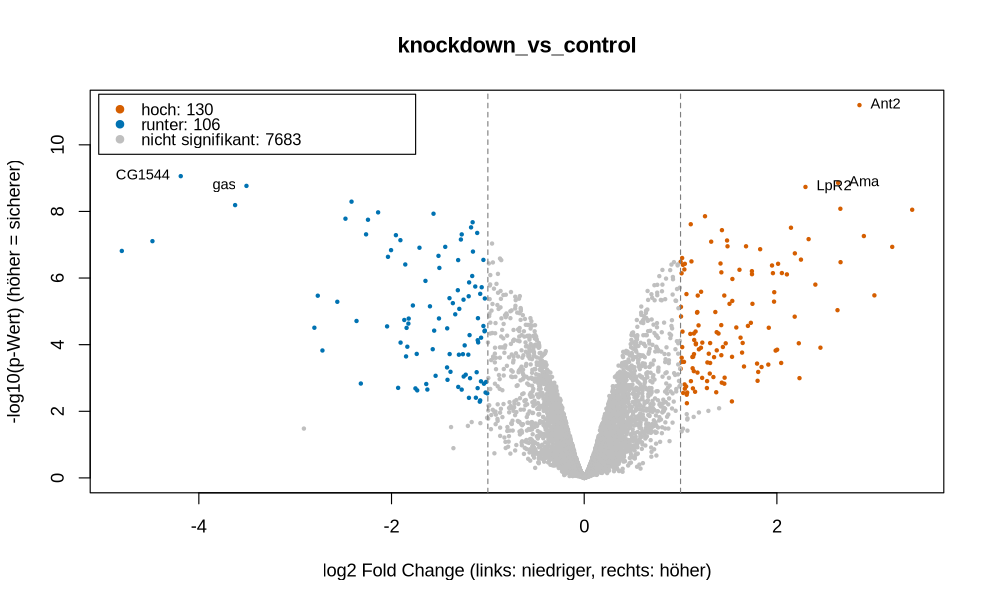

In [8]:
plotVolcano(fit, "knockdown_vs_control")
showTop(fit, "knockdown_vs_control", n = 15, direction = "up")
showTop(fit, "knockdown_vs_control", n = 15, direction = "down")
top <- topTable(fit, coef = "knockdown_vs_control", number = Inf)
top[top$symbol == "ps", c("symbol", "logFC", "adj.P.Val")]

<details><summary>💡 <b>Tipp</b> (zum Öffnen klicken)</summary>

Um ein Gen in der vollständigen Ergebnistabelle zu finden: `top <- topTable(fit, coef = "knockdown_vs_control", number = Inf)`, dann `top[top$symbol == "ps", ]`. Viele Fliegengene heißen nur `CG…` + eine Nummer: Niemand weiß bisher, was sie tun!

</details>

## Dein Fazit

Beantworte die Forschungsfrage in ein paar Sätzen: Was hast du verglichen, was hast du gefunden, und was bedeutet es? Sei bereit, deinen Vulkan-Plot und deine Antwort der Klasse zu zeigen.

✅ **Antwort:** Wir haben 3 pasilla-Knockdown-Proben mit 4 Kontrollen verglichen, mit der Bibliotheksart im Design, um den Batch-Effekt zu entfernen. Der Knockdown hat funktioniert: `ps` selbst ist etwa **3,7-mal niedriger** (logFC ≈ −1,9). Etwa 660 Gene gingen hoch und 600 runter. Zu den stärksten Veränderungen gehören *Ant2* und *sesB*, zwei Versionen desselben Transporters in den Mitochondrien (einer hoch, einer runter), sowie *Kal1*, *Hml* und *SPARC*. Viele veränderte Gene sind noch unerforscht (`CG…`). Da pasilla das Spleißen steuert, könnten viele dieser Gene seine Ziele sein: Mit so einer Liste beginnen Forschende, um herauszufinden, was ein unbekanntes Protein tut.

## Bonus: Was, wenn du den Batch-Effekt ignorierst?

Wiederhole die Schritte 4 und 5 mit `model.matrix(~0 + condition, data = dge$samples)` und vergleiche die Zahl der signifikanten Gene.

In [9]:
design0 <- model.matrix(~0 + condition, data = dge$samples)
contrasts0 <- makeContrasts(knockdown_vs_control = conditionknockdown - conditioncontrol, levels = design0)
fit0 <- eBayes(contrasts.fit(lmFit(voom(dge, design0), design0), contrasts0))
summary(decideTests(fit0))

       knockdown_vs_control
Down                    321
NotSig                 7249
Up                      349

✅ **Antwort:** Ohne die Bibliotheksart sind nur etwa **670** Gene signifikant statt etwa **1.260**: Der Batch-Effekt zählt als Rauschen und verdeckt echte Veränderungen. Gute Experimente vermeiden Batch-Effekte, und gute Analysen berücksichtigen die, die sich nicht vermeiden lassen.

<small>Software: limma (Ritchie et al. 2015) mit voom (Law et al. 2014) und edgeR (Chen et al. 2025) in R. Vollständige Quellen aller Datensätze am Ende von `01_tutorial_milk.ipynb`.</small>